In [29]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [30]:
raw_data=pd.read_excel(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\palmeras\1F54.xlsx')
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 8899 entries, 0 to 8898
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  8899 non-null   str  
 1   Message  8899 non-null   str  
 2   Status   8899 non-null   str  
dtypes: str(3)
memory usage: 208.7 KB


In [31]:
aux=pd.DataFrame()
aux=raw_data
aux['Headers']='NaN'

for i in range(0,aux.shape[0]):
    aux.iloc[i,3]=aux.iloc[i,2][0:8]

aux['Headers'].value_counts()

Headers
0x252513    7638
0x252501     807
0x252511     419
0x252514      35
Name: count, dtype: int64

In [32]:
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 8899 entries, 0 to 8898
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  8899 non-null   str  
 1   Message  8899 non-null   str  
 2   Status   8899 non-null   str  
 3   Headers  8899 non-null   str  
dtypes: str(4)
memory usage: 278.2 KB


Odometer

In [33]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
unit_aux['Odometer in meters']=0.0
odometer=[]
date=[]
raw=[]
unit=pd.DataFrame()

for i in range(0,unit_aux.shape[0]):
    odometer.append(int(unit_aux.iloc[i,2][96:104],16))
    date.append(unit_aux.iloc[i,2][106:118])
    raw.append(unit_aux.iloc[i,2])    

unit_aux['Odometer in meters']=odometer
unit_aux['Date']=date
unit_aux['Raw data']=raw

#print(unit_aux['Odometer in meters'])

unit=unit_aux.sort_values('Date',ascending=True)

print(unit.info())

<class 'pandas.DataFrame'>
Index: 7673 entries, 0 to 8898
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Created             7673 non-null   str  
 1   Message             7673 non-null   str  
 2   Status              7673 non-null   str  
 3   Headers             7673 non-null   str  
 4   Odometer in meters  7673 non-null   int64
 5   Date                7673 non-null   str  
 6   Raw data            7673 non-null   str  
dtypes: int64(1), str(6)
memory usage: 479.6 KB
None


261101035357 -> 0 -> 809866.0 -> 0x25251300595D510869487063261126003C38402D0000002C4E00000087000020002000FFFFFFFFFFFFFFFFFFFF00D5000C5B8A0026110103535700809D430F0493C259527540000000CC03952588FFFFFF00001B0000FFFFFF
261101075357 -> 1 -> 809866.0 -> 0x25251300595D520869487063261126003C38402D0000001B4E00000087000020002000FFFFFFFFFFFFFFFFFFFF00D5000C5B8A0026110107535700809D430F0493C259527540000000CC03952586FFFFFF00001A0000FFFFFF
261101115358 -> 2 -> 809866.0 -> 0x25251300595D530869487063261126003C38402D000000334F00000087000020002000FFFFFFFFFFFFFFFFFFFF00D5000C5B8A0026110111535800809D430F0493C259527540000000CC03952581FFFFFF0000190000FFFFFF
261101155358 -> 3 -> 809866.0 -> 0x25251300595D540869487063261126003C38402D000000254F00000087000020002000FFFFFFFFFFFFFFFFFFFF00D5000C5B8A0026110115535800809D430F0493C259527540000000CC03952571FFFFFF0000220000FFFFFF
261101195358 -> 4 -> 809866.0 -> 0x25251300595D550869487063261126003C38402D0000002C5000000087000020002000FFFFFFFFFFFFFFFFFFFF00D5000C5B8A0026110

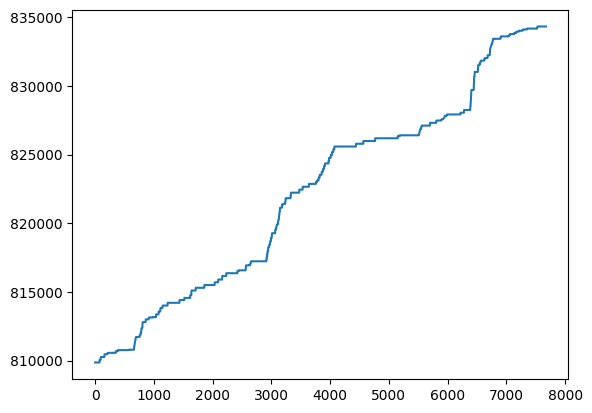

In [34]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append(float(unit.iloc[i,4]))
    x_axis.append(i)
    date.append(unit.iloc[i,5])
    raw_data_.append(unit.iloc[i,6])

#print("Delta odometer: ",y_axis[170]-y_axis[133],'meters')

for i in range(0,len(odometer)):
    print(date[i],'->',x_axis[i],'->',y_axis[i],'->',raw_data_[i])

print(odometer[len(odometer)-1]-odometer[0])
plt.plot(x_axis,y_axis)

Speed

In [35]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
#unit_aux['Odometer in meters']=0.0
speed=[]
date=[]
raw=[]
unit_speed=pd.DataFrame()
unit=pd.DataFrame()

for i in range(0,unit_aux.shape[0]):
    try:
        lbs_ind=(bin(int(unit_aux.iloc[i,2][50:52],16) & 64))
        if lbs_ind=='0b1000000':
            speed.append(int(unit_aux.iloc[i,2][142:145]))  
            date.append(unit_aux.iloc[i,2][106:118])
            raw.append(unit_aux.iloc[i,2])
            #print(lbs_ind)

    except:
        pass    

unit_speed['Speed']=speed
unit_speed['Date']=date
unit_speed['Raw data']=raw

unit=unit_speed.sort_values('Date',ascending=True)

print(unit.info())

<class 'pandas.DataFrame'>
Index: 7673 entries, 0 to 7672
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Speed     7673 non-null   int64
 1   Date      7673 non-null   str  
 2   Raw data  7673 non-null   str  
dtypes: int64(1), str(2)
memory usage: 239.8 KB
None


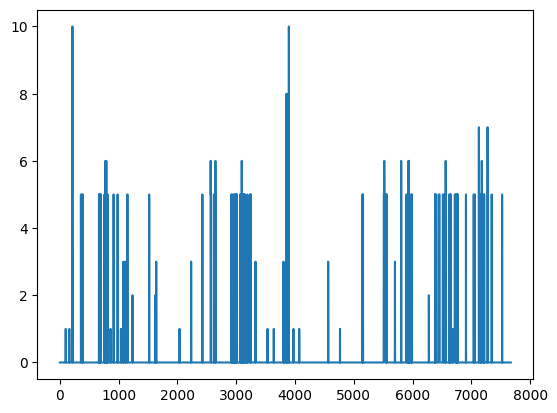

In [36]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append(float(unit.iloc[i,0]))
    x_axis.append(i)
    date.append(unit.iloc[i,1])
    raw_data_.append(unit.iloc[i,2])
    #print(raw_data_[i])

for i in range(0,len(speed)):
    if (y_axis[i]>55):
        print(date[i],'->',x_axis[i],'->',y_axis[i],'->',raw_data_[i])

plt.plot(x_axis,y_axis)

Satellites

In [37]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
satellite_number=[]
satellite_connection_indicator=[]
date=[]
raw=[]
num_events=0

for i in range(0,unit_aux.shape[0]):
    satellite_number.append(int(unit_aux.iloc[i,2][50:52],16) & 31)
    satellite_connection_indicator.append(int(unit_aux.iloc[i,2][50:52],16) & 128)
    date.append(unit_aux.iloc[i,2][106:118])
    raw.append(unit_aux.iloc[i,2])    

unit_aux['Satellites']=satellite_number
unit_aux['Satellite_connection_indicator']=satellite_connection_indicator
unit_aux['Raw data']=raw
unit_aux['date']=date

unit=unit_aux.sort_values('date',ascending=True)
unit.info()

for i in range(0,unit.shape[0]):
    if unit.iloc[i,4]<1:
        num_events=num_events+1
        print(unit.iloc[i,0], '->',unit.iloc[i,4],'->',unit.iloc[i,5],'->',unit.iloc[i,6])

print("Eventos históricos: ",num_events)

<class 'pandas.DataFrame'>
Index: 7673 entries, 0 to 8898
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   Created                         7673 non-null   str  
 1   Message                         7673 non-null   str  
 2   Status                          7673 non-null   str  
 3   Headers                         7673 non-null   str  
 4   Satellites                      7673 non-null   int64
 5   Satellite_connection_indicator  7673 non-null   int64
 6   Raw data                        7673 non-null   str  
 7   date                            7673 non-null   str  
dtypes: int64(2), str(6)
memory usage: 539.5 KB
Eventos históricos:  0


In/Outs

15      14                 13      12      11      10      09      08       07 06 05 04 03 02 01 00
Power   Ignition/Input0    Input1  Input2  Input3  Input4  Input5  Input0

15=0, Connected
15=1. Disconnected

In [38]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
unit_aux.info()
aux_cad=[]
aux_date=[]
aux_raw_data=[]
aux_input_number=[]
in_outs=[]

#unit_aux.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sym\concatenated.csv')

for i in range(0,unit_aux.shape[0]):
    long_cad=len(unit_aux.iloc[i,2])
    if ((long_cad>48) & (long_cad<204)):
        aux_cad.append(unit_aux.iloc[i,2])   

for i in range(0,len(aux_cad)):
    aux_value=aux_cad[i][64:68]
    aux_date.append(aux_cad[i][106:118])
    aux_raw_data.append(aux_cad[i])
    in_outs.append(bin (int (aux_cad[i][64:68],16)))      

unit_=pd.DataFrame()
unit_['in and outs']=in_outs
unit_['date']=aux_date
unit_['raw data']=aux_raw_data

in_outs_df=unit_.sort_values('date',ascending=True)

in_outs_df.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\palmeras\in_outs.csv')

<class 'pandas.DataFrame'>
Index: 7673 entries, 0 to 8898
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  7673 non-null   str  
 1   Message  7673 non-null   str  
 2   Status   7673 non-null   str  
 3   Headers  7673 non-null   str  
dtypes: str(4)
memory usage: 299.7 KB


Ignition

In [39]:
in_outs_df.info()

for i in range(0,in_outs_df.shape[0]):
    length=len(in_outs_df.iloc[i,0])
    if length>16:
        aux_ign=in_outs_df.iloc[i,0][2:3]
        if aux_ign=='1':
            print("Ignition On",in_outs_df.iloc[i,0])
        if aux_ign=='0':
            print("Ignition Off",in_outs_df.iloc[i,0])
    else:
        aux_ign=in_outs_df.iloc[i,0][2:3]
        if aux_ign=='1':
            print("Ignition On",in_outs_df.iloc[i,0])
        if aux_ign=='0':
            print("Ignition Off",in_outs_df.iloc[i,0])

<class 'pandas.DataFrame'>
Index: 7673 entries, 0 to 7672
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   in and outs  7673 non-null   str  
 1   date         7673 non-null   str  
 2   raw data     7673 non-null   str  
dtypes: str(3)
memory usage: 239.8 KB
Ignition On 0b10000000000000
Ignition On 0b10000000000000
Ignition On 0b10000000000000
Ignition On 0b10000000000000
Ignition On 0b10000000000000
Ignition On 0b10000000000000
Ignition On 0b10000000000000
Ignition On 0b10000000000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000100000000
Ignition On 0b110000

Power

In [40]:
ext_bat_13=raw_data[raw_data['Status'].str.contains('0x252513')]
ext_bat_14=raw_data[raw_data['Status'].str.contains('0x252514')]
ext_bat_vol=pd.concat([ext_bat_13,ext_bat_14])
ext_bat=[]
date_bat=[]
bat_df=pd.DataFrame()

ext_bat_vol.info()

for i in range(0,ext_bat_vol.shape[0]):
    val=(float(ext_bat_vol.iloc[i,2][154:158]))/100
    date_bat.append(ext_bat_vol.iloc[i,2][106:119])
    ext_bat.append(val)
#print(ext_bat)

for i in range(0,ext_bat_vol.shape[0]):
    if ext_bat[i]<3:
        bat_df['Date']=date_bat
        bat_df['int_bat']=ext_bat

print(bat_df)

<class 'pandas.DataFrame'>
Index: 7673 entries, 0 to 8898
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  7673 non-null   str  
 1   Message  7673 non-null   str  
 2   Status   7673 non-null   str  
 3   Headers  7673 non-null   str  
dtypes: str(4)
memory usage: 299.7 KB
Empty DataFrame
Columns: []
Index: []


Pánico

In [41]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
unit_aux.info()
aux_cad=[]
aux_date=[]
aux_raw_data=[]
aux_input_number=[]

#unit_aux.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sym\concatenated.csv')

for i in range(0,unit_aux.shape[0]):
    long_cad=len(unit_aux.iloc[i,2])
    if ((long_cad>48) & (long_cad<204)):
        aux_cad.append(unit_aux.iloc[i,2])   

for i in range(0,len(aux_cad)):
    aux_value=aux_cad[i][92:94]
    aux_date.append(aux_cad[i][106:118])
    #aux_raw_data.append(aux_cad[i])
    if aux_value=='03':
        print(aux_value, ' -> ',aux_date[i])    

print("len aux_cad: ",len(aux_cad))

<class 'pandas.DataFrame'>
Index: 7673 entries, 0 to 8898
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  7673 non-null   str  
 1   Message  7673 non-null   str  
 2   Status   7673 non-null   str  
 3   Headers  7673 non-null   str  
dtypes: str(4)
memory usage: 299.7 KB
03  ->  261111135247
len aux_cad:  7673


Historical locations

In [42]:
hl=pd.read_excel(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\palmeras\historicallocations.xlsx')
hl.info()

<class 'pandas.DataFrame'>
RangeIndex: 7195 entries, 0 to 7194
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Sequence     7195 non-null   int64  
 1   Unit         7195 non-null   str    
 2   Events       7195 non-null   str    
 3   Date         7195 non-null   str    
 4   Landmark     0 non-null      float64
 5   Address      7195 non-null   str    
 6   Speed        7195 non-null   int64  
 7   Temperature  0 non-null      float64
 8   Driver       0 non-null      float64
 9   Latitude     7195 non-null   float64
 10  Longitude    7195 non-null   float64
dtypes: float64(5), int64(2), str(4)
memory usage: 618.4 KB


In [43]:
hl['Events'].value_counts()

Events
Idle - Stop           6766
Drive                  319
Parked                  75
Ignición Apagada        17
Ignición Encendida      17
Botón de pánico          1
Name: count, dtype: int64